In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Replace 'your_file.csv' with your file path
df = pd.read_csv(r"C:\Users\PatrickOrenstein\OneDrive - ZeroEx GmbH\ZeroEx - ZX_Scientific\03_CDR_Calculation\03_EW_Model\02_Weather_Statistics\Olsdorf_01964_weather_data\daily\Olsdorf_daily.txt", delimiter=';')
df.columns = df.columns.str.replace(' ', '')

# print(df.head())  # Shows the first few rows
df['date'] = pd.to_datetime(df['MESS_DATUM'].astype(str), format='%Y%m%d')
df['rain_mm'] = df['RSK']
# df = df[['date','rain_mm']]
df['mean_temp'] = df['TMK']
df['max_temp'] = df['TXK']
df['min_temp'] = df['TNK']
df['mean_wind_ms'] = df['FM']
df['daily_temp_range'] = np.abs(df['max_temp'] - df['min_temp'])

df = df[df.date<'1990'] # year after which there start to be some missing months/days
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year

n_years = df.year.nunique()

# monthly_summary = df.groupby('month').agg(
#     total_rain_mm=('rain_mm', 'sum'),
#     min_rain_mm=('rain_mm', 'min'),
#     max_rain_mm=('rain_mm', 'max'),
#     std_rain_mm=('rain_mm', 'std'),
#     rain_days=('rain_mm', lambda x: (x > 0).sum()),
#     total_days=('rain_mm', 'count'),
    
#     mean_daily_temp = ('mean_temp','mean'),
#     max_daily_temp = ('mean_temp','max'),
#     min_daily_temp = ('mean_temp','min'),
#     std_daily_temp = ('mean_temp','std')
# )



# ---- fixed aggregation ----
monthly_summary = df.groupby('month').agg(
    total_rain_mm=('rain_mm', 'sum'),
    min_rain_mm=('rain_mm', 'min'),
    max_rain_mm=('rain_mm', 'max'),
    std_rain_mm=('rain_mm', 'std'),
    rain_days=('rain_mm', lambda x: (x > 0.1).sum()),
    total_days=('rain_mm', 'count'),

    mean_daily_temp=('mean_temp', 'mean'),
    max_daily_temp=('mean_temp', 'max'),
    min_daily_temp=('mean_temp', 'min'),
    std_daily_temp=('mean_temp', 'std')
)



# Calculate probability of rain
monthly_summary['rain_probability'] = monthly_summary['rain_days'] / monthly_summary['total_days']
monthly_summary['conditional_mean_rain_mm'] = monthly_summary['total_rain_mm'] / monthly_summary['rain_days'] # conditional mean
monthly_summary['unconditional_mean_rain_mm'] = monthly_summary['total_rain_mm'] / monthly_summary['total_days'] # unconditional mean

monthly_summary['mean_monthly_rain_mm'] = monthly_summary['total_rain_mm'] / n_years

# monthly_summary = monthly_summary[['conditional_mean_rain_mm','rain_probability']]


<Axes: xlabel='month'>

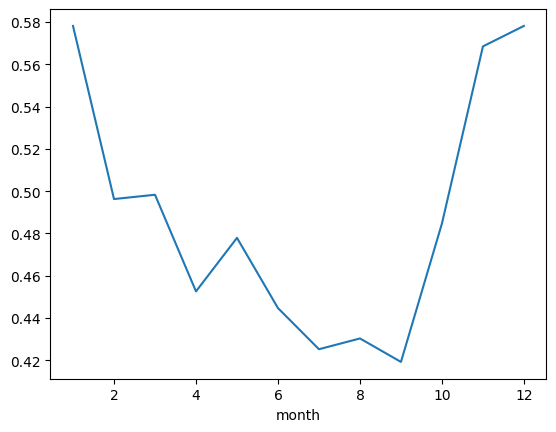

In [2]:
monthly_summary['rain_probability'].plot()

In [3]:
year_summary = df.groupby('year').agg(
    annual_mean_temp = ('mean_temp', 'mean'),
    annual_max_temp = ('mean_temp', 'max'),
    annual_min_temp = ('mean_temp', 'min'),
)

year_summary['annual_temp_range'] = year_summary['annual_max_temp'] - year_summary['annual_min_temp']


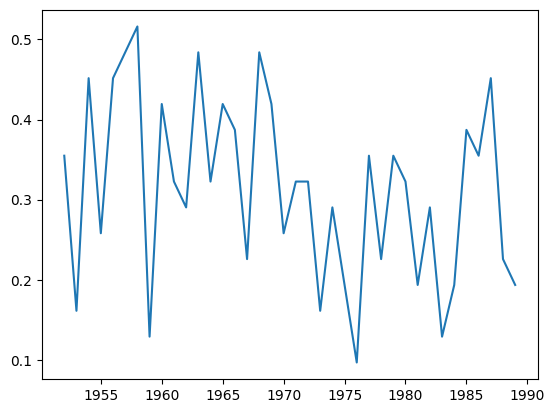

In [4]:
plt.figure()

df_subset = df[df['month']==8]

summary = df_subset.groupby('year').agg(
    rain_days=('rain_mm', lambda x: (x > 1).sum()),
    total_days=('rain_mm', 'count'),
    )

x = summary['rain_days'] / summary['total_days']

plt.plot(x)

    
    
# x = monthly_summary['rain_days'] / monthly_summary['total_days']

# plt.plot(x, color='black', linewidth=5)
    

plt.show()

    
    

In [5]:
df[df['month']==8]

,STATIONS_ID,MESS_DATUM,QN_3,FX,FM,QN_4,RSK,RSKF,SDK,SHK_TAG,...,eor,date,rain_mm,mean_temp,max_temp,min_temp,mean_wind_ms,daily_temp_range,month,year
213,1964,19520801,-999,-999,-999,5,0.0,0,-999,0,...,eor,1952-08-01,0.0,17.5,26.4,8.2,-999,18.2,8,1952
214,1964,19520802,-999,-999,-999,5,0.5,1,-999,0,...,eor,1952-08-02,0.5,19.4,27.0,8.5,-999,18.5,8,1952
215,1964,19520803,-999,-999,-999,5,0.0,0,-999,0,...,eor,1952-08-03,0.0,16.8,23.5,14.0,-999,9.5,8,1952
216,1964,19520804,-999,-999,-999,5,0.0,0,-999,0,...,eor,1952-08-04,0.0,17.6,25.9,8.7,-999,17.2,8,1952
217,1964,19520805,-999,-999,-999,5,0.0,1,-999,0,...,eor,1952-08-05,0.0,19.0,28.4,8.5,-999,19.9,8,1952
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13753,1964,19890827,-999,-999,-999,10,1.6,6,-999,0,...,eor,1989-08-27,1.6,13.2,17.5,10.6,-999,6.9,8,1989
13754,1964,19890828,-999,-999,-999,10,0.3,6,-999,0,...,eor,1989-08-28,0.3,13.0,17.9,8.4,-999,9.5,8,1989
13755,1964,19890829,-999,-999,-999,10,0.2,6,-999,0,...,eor,1989-08-29,0.2,11.4,17.0,7.3,-999,9.7,8,1989
13756,1964,19890830,-999,-999,-999,10,0.0,0,-999,0,...,eor,1989-08-30,0.0,15.7,20.1,9.1,-999,11.0,8,1989


In [6]:
df

,STATIONS_ID,MESS_DATUM,QN_3,FX,FM,QN_4,RSK,RSKF,SDK,SHK_TAG,...,eor,date,rain_mm,mean_temp,max_temp,min_temp,mean_wind_ms,daily_temp_range,month,year
0,1964,19520101,-999,-999,-999,5,3.8,8,-999,0,...,eor,1952-01-01,3.8,2.0,5.6,-0.3,-999,5.9,1,1952
1,1964,19520102,-999,-999,-999,5,17.3,1,-999,0,...,eor,1952-01-02,17.3,5.1,6.8,0.3,-999,6.5,1,1952
2,1964,19520103,-999,-999,-999,5,1.2,1,-999,0,...,eor,1952-01-03,1.2,1.6,6.2,0.6,-999,5.6,1,1952
3,1964,19520104,-999,-999,-999,5,2.2,8,-999,1,...,eor,1952-01-04,2.2,0.6,2.3,0.0,-999,2.3,1,1952
4,1964,19520105,-999,-999,-999,5,1.1,1,-999,0,...,eor,1952-01-05,1.1,1.7,2.8,0.3,-999,2.5,1,1952
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13875,1964,19891227,-999,-999,-999,10,0.0,0,-999,0,...,eor,1989-12-27,0.0,-1.8,-1.3,-2.7,-999,1.4,12,1989
13876,1964,19891228,-999,-999,-999,10,0.0,0,-999,0,...,eor,1989-12-28,0.0,-1.6,-0.9,-2.1,-999,1.2,12,1989
13877,1964,19891229,-999,-999,-999,10,0.0,0,-999,0,...,eor,1989-12-29,0.0,-0.6,-0.3,-2.3,-999,2.0,12,1989
13878,1964,19891230,-999,-999,-999,10,0.0,0,-999,0,...,eor,1989-12-30,0.0,-0.2,0.2,-1.4,-999,1.6,12,1989


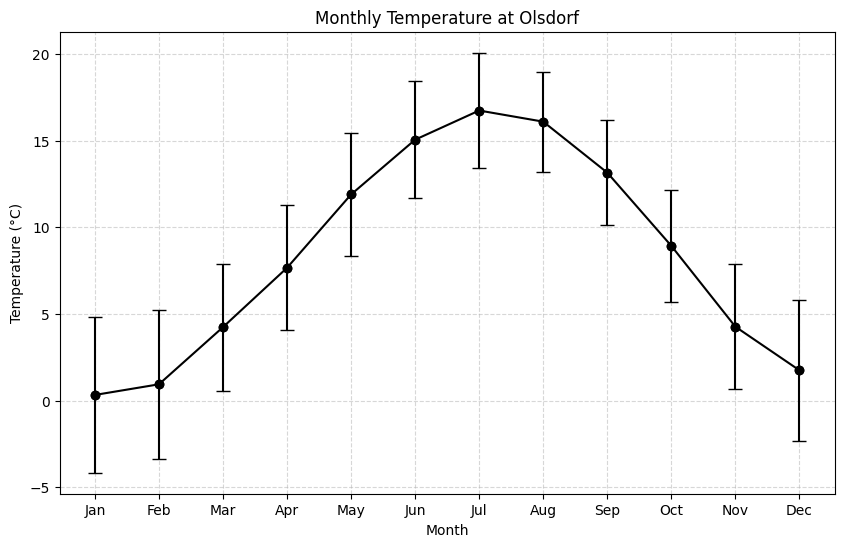

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Example data: months, min temps, max temps
months = np.arange(1, 13)  # Month numbers for indexing
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

mean_temps = monthly_summary.mean_daily_temp.values
min_temps = monthly_summary.min_daily_temp.values
max_temps = monthly_summary.max_daily_temp.values

# Calculate the whisker lengths (differences from the mean)
yerr_lower = mean_temps - min_temps
yerr_upper = max_temps - mean_temps

yerr_lower = monthly_summary.std_daily_temp.values
yerr_upper = monthly_summary.std_daily_temp.values


# Combine lower and upper errors into a 2D array for asymmetric error bars
yerr = np.vstack((yerr_lower, yerr_upper))

# Create the plot
plt.figure(figsize=(10, 6))

# Plot mean temperatures with error bars (whiskers)
plt.errorbar(months, mean_temps, yerr=yerr, fmt='o', capsize=5, color='black')

# # Create the plot
# plt.figure(figsize=(10, 6))

# # Fill between min and max temperatures
# plt.fill_between(months, min_temps, max_temps, alpha=0.3, label='Temperature Range')

# # Plot the min and max temperature lines
plt.plot(months, mean_temps, marker='o', label='Mean Temperature', color='black')
# plt.plot(months, max_temps, marker='o', label='Max Temperature')

# Customize plot
plt.title('Monthly Temperature at Olsdorf')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')

# Set x-ticks to month abbreviations
plt.xticks(months, month_labels)

plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend()

# Show plot
plt.show()


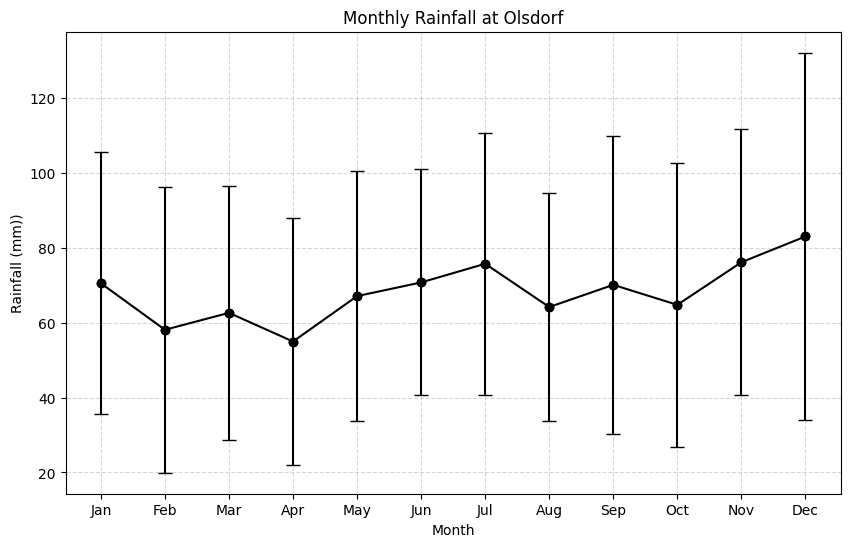

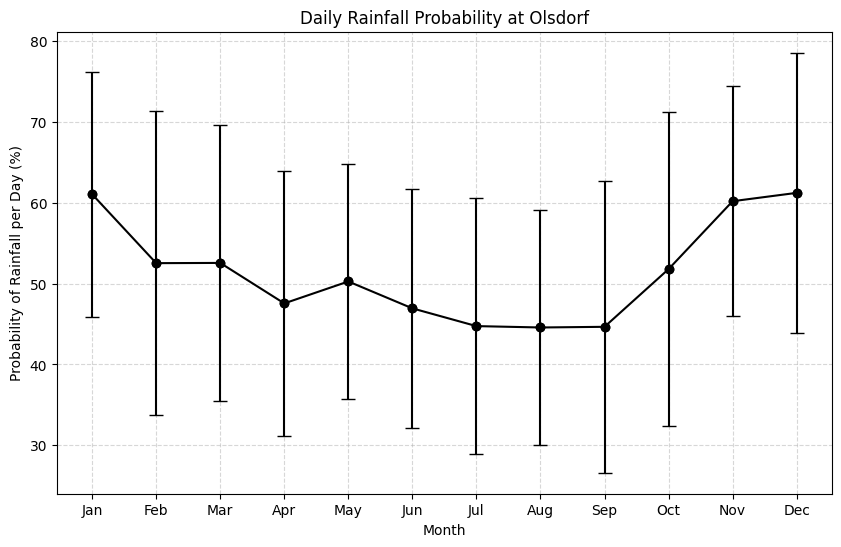

In [8]:
import matplotlib.pyplot as plt
import numpy as np

df['year_month'] = df['date'].dt.to_period('M')
monthyear_summary = df.groupby('year_month').agg(
    total_rain_mm=('rain_mm', 'sum'),
    rain_days=('rain_mm', lambda x: (x > 0).sum()),
    total_days=('rain_mm', 'count')
)

# Calculate probability of rain
monthyear_summary['rain_probability'] = monthyear_summary['rain_days'] / monthyear_summary['total_days']

monthyear_summary = monthyear_summary.reset_index()
monthyear_summary['month'] = monthyear_summary['year_month'].dt.month


monthyear_monthly_summary = monthyear_summary.groupby('month').agg(
    mean_monthly_total_rain_mm=('total_rain_mm', 'mean'),
    std_monthly_total_rain_mm=('total_rain_mm', 'std'),

    mean_monthly_rain_probability=('rain_probability', 'mean'),
    std_monthly_rain_probability=('rain_probability', 'std'),

)



# Example data: months, min temps, max temps
months = np.arange(1, 13)  # Month numbers for indexing
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

mean_rainfall = monthyear_monthly_summary.mean_monthly_total_rain_mm.values

yerr_lower = monthyear_monthly_summary.std_monthly_total_rain_mm.values
yerr_upper = monthyear_monthly_summary.std_monthly_total_rain_mm.values


# Combine lower and upper errors into a 2D array for asymmetric error bars
yerr = np.vstack((yerr_lower, yerr_upper))

# Create the plot
plt.figure(figsize=(10, 6))

# Plot mean temperatures with error bars (whiskers)
plt.errorbar(months, mean_rainfall, yerr=yerr, fmt='o', capsize=5, color='black')

# # Create the plot
# plt.figure(figsize=(10, 6))

# # Fill between min and max temperatures
# plt.fill_between(months, min_temps, max_temps, alpha=0.3, label='Temperature Range')

# # Plot the min and max temperature lines
plt.plot(months, mean_rainfall, marker='o', label='Mean Temperature', color='black')
# plt.plot(months, max_temps, marker='o', label='Max Temperature')

# Customize plot
plt.title('Monthly Rainfall at Olsdorf')
plt.xlabel('Month')
plt.ylabel('Rainfall (mm))')

# Set x-ticks to month abbreviations
plt.xticks(months, month_labels)

plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend()

# Show plot
plt.show()




################# Probability


mean_rainfall = monthyear_monthly_summary.mean_monthly_rain_probability.values * 100

yerr_lower = monthyear_monthly_summary.std_monthly_rain_probability.values*100
yerr_upper = monthyear_monthly_summary.std_monthly_rain_probability.values*100


# Combine lower and upper errors into a 2D array for asymmetric error bars
yerr = np.vstack((yerr_lower, yerr_upper))

# Create the plot
plt.figure(figsize=(10, 6))

# Plot mean temperatures with error bars (whiskers)
plt.errorbar(months, mean_rainfall, yerr=yerr, fmt='o', capsize=5, color='black')

# # Create the plot
# plt.figure(figsize=(10, 6))

# # Fill between min and max temperatures
# plt.fill_between(months, min_temps, max_temps, alpha=0.3, label='Temperature Range')

# # Plot the min and max temperature lines
plt.plot(months, mean_rainfall, marker='o', label='Mean Temperature', color='black')
# plt.plot(months, max_temps, marker='o', label='Max Temperature')

# Customize plot
plt.title('Daily Rainfall Probability at Olsdorf')
plt.xlabel('Month')
plt.ylabel('Probability of Rainfall per Day (%)')

# Set x-ticks to month abbreviations
plt.xticks(months, month_labels)

plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend()

# Show plot
plt.show()



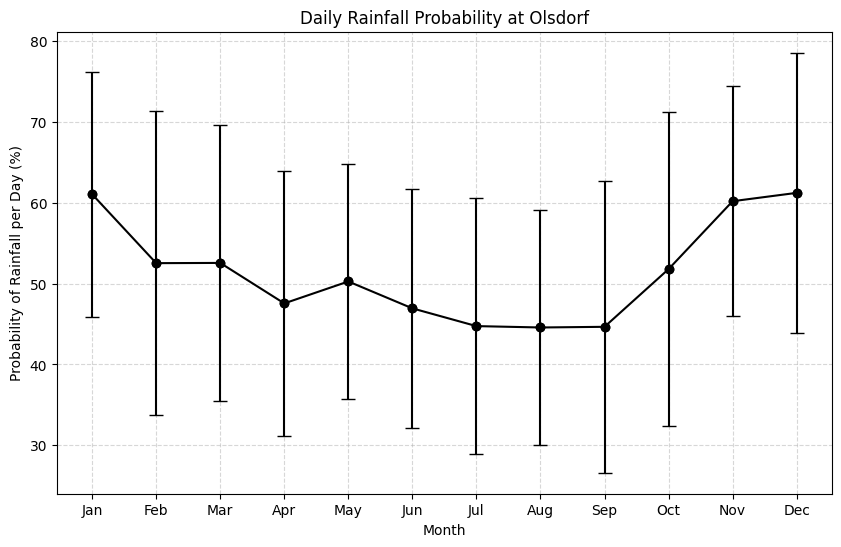

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Example data: months, min temps, max temps
months = np.arange(1, 13)  # Month numbers for indexing
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

mean_rainfall = monthyear_monthly_summary.mean_monthly_rain_probability.values * 100

yerr_lower = monthyear_monthly_summary.std_monthly_rain_probability.values*100
yerr_upper = monthyear_monthly_summary.std_monthly_rain_probability.values*100


# Combine lower and upper errors into a 2D array for asymmetric error bars
yerr = np.vstack((yerr_lower, yerr_upper))

# Create the plot
plt.figure(figsize=(10, 6))

# Plot mean temperatures with error bars (whiskers)
plt.errorbar(months, mean_rainfall, yerr=yerr, fmt='o', capsize=5, color='black')

# # Create the plot
# plt.figure(figsize=(10, 6))

# # Fill between min and max temperatures
# plt.fill_between(months, min_temps, max_temps, alpha=0.3, label='Temperature Range')

# # Plot the min and max temperature lines
plt.plot(months, mean_rainfall, marker='o', label='Mean Temperature', color='black')
# plt.plot(months, max_temps, marker='o', label='Max Temperature')

# Customize plot
plt.title('Daily Rainfall Probability at Olsdorf')
plt.xlabel('Month')
plt.ylabel('Probability of Rainfall per Day (%)')

# Set x-ticks to month abbreviations
plt.xticks(months, month_labels)

plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend()

# Show plot
plt.show()
